# Homework 5.2 - Steps 5-6

## Markov Next-Token Models and Context-Length Comparison

This notebook constructs next-token predictors from the training token books and studies how prediction changes when more history is used.

For a first-order model,

$$
P(a_{n+1}=b\mid a_n=a)
=
\frac{
\#\{a\rightarrow b\}
}{
\#\{\text{times }a\text{ is a current token}\}
}.
$$

For an order-$$m$$ model,

$$
P(
a_{n+1}=b
\mid
a_{n-m+1},\ldots,a_n
)
=
\frac{
\#\{
(a_{n-m+1},\ldots,a_n,b)
\}
}{
\#\{
(a_{n-m+1},\ldots,a_n)
\}
}.
$$

We compare

$$
m=1,2,3.
$$

No context is allowed to cross the boundary between two trajectory books.

## Model-selection protocol

The training books estimate all transition counts.

The validation books are used to compare the predeclared values

$$
m\in\{1,2,3\}.
$$

The selected baseline context length is the one with the highest validation next-token accuracy. If two values tie, the smaller $$m$$ is selected.

Only after this selection is fixed is the test split loaded for final evaluation.

For unseen length-$$m$$ histories, prediction uses deterministic **backoff**:

1. try the full history;
2. if unseen, drop the oldest token and try a shorter history;
3. continue until a seen history is found;
4. if no history is available, use the most frequent training token.

This prevents an unseen history from causing an undefined prediction while still allowing us to separately report exact-history coverage.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw5_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw5_2"
TOKEN_DIR = DATA_DIR / "token_books"

CONFIG_PATH = DATA_DIR / "baseline_configuration.json"

if not CONFIG_PATH.exists():
    raise FileNotFoundError(
        "Run Steps 2-4 before this notebook."
    )

configuration = json.loads(
    CONFIG_PATH.read_text(
        encoding="utf-8"
    )
)

VOCAB_SIZE = int(
    configuration[
        "possible_vocabulary_size"
    ]
)

CONTEXT_LENGTHS = [1, 2, 3]

print("Vocabulary size:", VOCAB_SIZE)

Vocabulary size: 1728


In [2]:
def load_token_books(split_name):
    split_dir = TOKEN_DIR / split_name

    paths = sorted(
        split_dir.glob("book_*.csv")
    )

    if not paths:
        raise FileNotFoundError(
            f"No token books found in {split_dir}"
        )

    books = []

    for path in paths:
        frame = pd.read_csv(path)

        books.append(
            frame["token"].to_numpy(
                dtype=np.int64
            )
        )

    return books


train_books = load_token_books("train")
validation_books = load_token_books("validation")

print("Training books:", len(train_books))
print("Validation books:", len(validation_books))

# The test books are deliberately not loaded yet.

Training books: 40
Validation books: 10


## Fit the family of $$m$$-gram models

For each context length, counts are accumulated inside each training book separately.

Thus the final token of one book is never treated as preceding the first token of another book.

In [3]:
def fit_ngram_model(books, max_order):
    models = {
        order: defaultdict(Counter)
        for order in range(
            1,
            max_order + 1,
        )
    }

    unigram_counts = Counter()

    for sequence in books:
        unigram_counts.update(
            sequence.tolist()
        )

        for order in range(
            1,
            max_order + 1,
        ):
            for i in range(
                order,
                len(sequence),
            ):
                history = tuple(
                    int(x)
                    for x in sequence[
                        i-order:i
                    ]
                )

                next_token = int(
                    sequence[i]
                )

                models[order][history][
                    next_token
                ] += 1

    global_mode = min(
        unigram_counts,
        key=lambda token: (
            -unigram_counts[token],
            token,
        ),
    )

    return models, unigram_counts, global_mode


models, unigram_counts, global_mode = fit_ngram_model(
    train_books,
    max(CONTEXT_LENGTHS),
)

print("Most frequent training token:", global_mode)

for order in CONTEXT_LENGTHS:
    print(
        f"m={order}: "
        f"{len(models[order]):,} "
        "distinct training histories"
    )

Most frequent training token: 940
m=1: 250 distinct training histories
m=2: 871 distinct training histories
m=3: 1,722 distinct training histories


In [4]:
def deterministic_mode(counter):
    return min(
        counter,
        key=lambda token: (
            -counter[token],
            token,
        ),
    )


def predict_with_backoff(
    history,
    requested_order,
):
    history = tuple(
        int(x)
        for x in history
    )

    for order in range(
        requested_order,
        0,
        -1,
    ):
        if len(history) < order:
            continue

        key = history[-order:]

        if key in models[order]:
            return (
                deterministic_mode(
                    models[order][key]
                ),
                order,
            )

    return global_mode, 0


def evaluate_books(
    books,
    requested_order,
):
    total = 0
    correct = 0
    exact_history_seen = 0
    backoff_order_counts = Counter()

    for sequence in books:
        for i in range(
            requested_order,
            len(sequence),
        ):
            history = sequence[
                i-requested_order:i
            ]

            truth = int(
                sequence[i]
            )

            exact_key = tuple(
                int(x)
                for x in history
            )

            if (
                exact_key
                in models[
                    requested_order
                ]
            ):
                exact_history_seen += 1

            prediction, used_order = (
                predict_with_backoff(
                    history,
                    requested_order,
                )
            )

            backoff_order_counts[
                used_order
            ] += 1

            correct += int(
                prediction == truth
            )

            total += 1

    return {
        "context_length_m": requested_order,
        "evaluated_positions": total,
        "accuracy": (
            correct / total
            if total
            else np.nan
        ),
        "exact_history_coverage": (
            exact_history_seen / total
            if total
            else np.nan
        ),
        "unseen_exact_history_fraction": (
            1.0
            - exact_history_seen / total
            if total
            else np.nan
        ),
        "backoff_order_counts": dict(
            backoff_order_counts
        ),
    }

## Validation comparison

The validation split is used to select the baseline context length.

A larger $$m$$ can represent longer memory, but the number of possible histories increases rapidly, which can reduce exact-history coverage.

In [5]:
validation_records = []

for order in CONTEXT_LENGTHS:
    record = evaluate_books(
        validation_books,
        order,
    )

    validation_records.append(
        record
    )

validation_table = pd.DataFrame([
    {
        "context_length_m": row[
            "context_length_m"
        ],
        "evaluated_positions": row[
            "evaluated_positions"
        ],
        "accuracy": row[
            "accuracy"
        ],
        "exact_history_coverage": row[
            "exact_history_coverage"
        ],
        "unseen_exact_history_fraction": row[
            "unseen_exact_history_fraction"
        ],
    }
    for row in validation_records
])

validation_path = (
    DATA_DIR
    / "task5_6_validation_context_results.csv"
)

validation_table.to_csv(
    validation_path,
    index=False,
)

print(validation_table.to_string(index=False))
print()
print("Saved:", validation_path.resolve())

 context_length_m  evaluated_positions  accuracy  exact_history_coverage  unseen_exact_history_fraction
                1                12500  0.614480                0.999600                       0.000400
                2                12490  0.699520                0.998479                       0.001521
                3                12480  0.757212                0.995433                       0.004567

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\task5_6_validation_context_results.csv


In [6]:
best_validation_accuracy = (
    validation_table["accuracy"].max()
)

selected_m = int(
    validation_table[
        np.isclose(
            validation_table["accuracy"],
            best_validation_accuracy,
        )
    ]["context_length_m"].min()
)

selection_record = {
    "selected_context_length_m": selected_m,
    "selection_rule": (
        "highest validation accuracy; "
        "smaller m breaks ties"
    ),
    "validation_accuracy": float(
        validation_table.loc[
            validation_table[
                "context_length_m"
            ]
            == selected_m,
            "accuracy",
        ].iloc[0]
    ),
    "candidate_context_lengths": (
        CONTEXT_LENGTHS
    ),
}

selection_path = (
    DATA_DIR
    / "task5_6_selected_markov_model.json"
)

selection_path.write_text(
    json.dumps(
        selection_record,
        indent=2,
    ),
    encoding="utf-8",
)

print("Selected m =", selected_m)
print("Saved:", selection_path.resolve())

Selected m = 3
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\task5_6_selected_markov_model.json


# Final test comparison

The context-length candidates and the selection rule are now fixed.

Only now is the test split loaded.

The test results are final evaluation results and are not used to revise the selected baseline model.

In [7]:
test_books = load_token_books("test")

test_records = []

for order in CONTEXT_LENGTHS:
    record = evaluate_books(
        test_books,
        order,
    )

    test_records.append(
        record
    )

test_table = pd.DataFrame([
    {
        "context_length_m": row[
            "context_length_m"
        ],
        "evaluated_positions": row[
            "evaluated_positions"
        ],
        "accuracy": row[
            "accuracy"
        ],
        "exact_history_coverage": row[
            "exact_history_coverage"
        ],
        "unseen_exact_history_fraction": row[
            "unseen_exact_history_fraction"
        ],
        "selected_by_validation": (
            row["context_length_m"]
            == selected_m
        ),
    }
    for row in test_records
])

test_path = (
    DATA_DIR
    / "task5_6_test_context_results.csv"
)

test_table.to_csv(
    test_path,
    index=False,
)

print(test_table.to_string(index=False))
print()
print("Saved:", test_path.resolve())

 context_length_m  evaluated_positions  accuracy  exact_history_coverage  unseen_exact_history_fraction  selected_by_validation
                1                12500  0.606960                0.999440                       0.000560                   False
                2                12490  0.694876                0.998078                       0.001922                   False
                3                12480  0.759135                0.994471                       0.005529                    True

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\task5_6_test_context_results.csv


## First-order transition example

For the most frequent training token $$a$$, the following table reports the most common observed next tokens and their empirical transition probabilities.

In [8]:
most_common_current = int(
    global_mode
)

history = (
    most_common_current,
)

transition_counter = models[1][
    history
]

transition_total = sum(
    transition_counter.values()
)

transition_rows = []

for next_token, count in (
    transition_counter.most_common(15)
):
    transition_rows.append({
        "current_token": most_common_current,
        "next_token": int(next_token),
        "transition_count": int(count),
        "empirical_probability": (
            count / transition_total
        ),
    })

transition_df = pd.DataFrame(
    transition_rows
)

transition_path = (
    DATA_DIR
    / "task5_first_order_transition_example.csv"
)

transition_df.to_csv(
    transition_path,
    index=False,
)

print(transition_df.to_string(index=False))
print()
print("Saved:", transition_path.resolve())

 current_token  next_token  transition_count  empirical_probability
           940         940              1358               0.734848
           940         939               352               0.190476
           940         952                46               0.024892
           940        1084                34               0.018398
           940        1096                29               0.015693
           940         951                15               0.008117
           940        1095                14               0.007576

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\task5_first_order_transition_example.csv


## Plot prediction accuracy versus context length

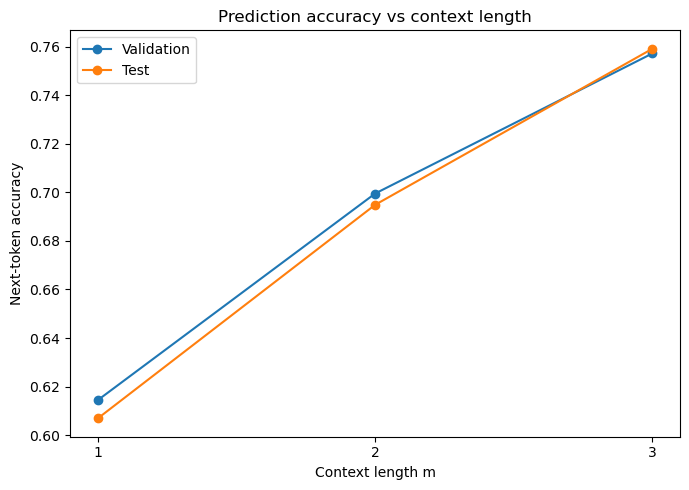

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step6_accuracy_vs_context_length.png


In [9]:
plt.figure(figsize=(7, 5))

plt.plot(
    validation_table[
        "context_length_m"
    ],
    validation_table["accuracy"],
    marker="o",
    label="Validation",
)

plt.plot(
    test_table[
        "context_length_m"
    ],
    test_table["accuracy"],
    marker="o",
    label="Test",
)

plt.xlabel("Context length m")
plt.ylabel("Next-token accuracy")
plt.title("Prediction accuracy vs context length")
plt.xticks(CONTEXT_LENGTHS)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step6_accuracy_vs_context_length.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Plot unseen-history fraction versus context length

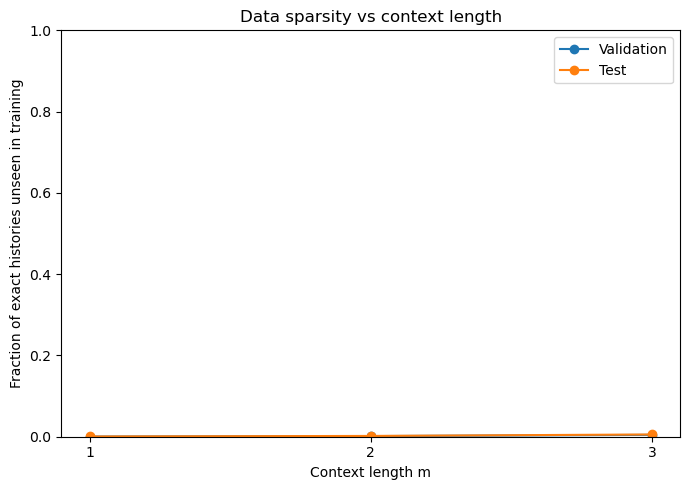

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step6_unseen_history_vs_context_length.png


In [10]:
plt.figure(figsize=(7, 5))

plt.plot(
    validation_table[
        "context_length_m"
    ],
    validation_table[
        "unseen_exact_history_fraction"
    ],
    marker="o",
    label="Validation",
)

plt.plot(
    test_table[
        "context_length_m"
    ],
    test_table[
        "unseen_exact_history_fraction"
    ],
    marker="o",
    label="Test",
)

plt.xlabel("Context length m")
plt.ylabel("Fraction of exact histories unseen in training")
plt.title("Data sparsity vs context length")
plt.xticks(CONTEXT_LENGTHS)
plt.ylim(0.0, 1.0)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step6_unseen_history_vs_context_length.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Steps 5-6 interpretation

The context-length experiment should be interpreted using both quantities:

1. next-token accuracy;
2. exact-history coverage.

A larger context is not automatically better. It contains more past information, but it also makes the number of possible histories much larger.

The validation-selected value of $$m$$ is saved for the generation experiment in Steps 7-8.

Task 10 will later keep this selected $$m$$ fixed while changing only the phase-space discretization. That isolates the effect of box resolution.

## Steps 5-6 outputs

### Data

- `task5_6_validation_context_results.csv`
- `task5_6_test_context_results.csv`
- `task5_6_selected_markov_model.json`
- `task5_first_order_transition_example.csv`

### Result images

- `step6_accuracy_vs_context_length.png`
- `step6_unseen_history_vs_context_length.png`